In [136]:
import pandas as pd 
import numpy as np
from scipy import stats

data = pd.read_csv("penyakit_jantung.csv")
thalach = data["thalach"]
thalach.head()

0    150
1    187
2    172
3    178
4    163
Name: thalach, dtype: int64

In [137]:
rata = np.mean(thalach)
median = np.median(thalach)
mode = stats.mode(thalach)
variance = np.var(thalach)
standar_deviasi = np.std(thalach)
skewness = stats.skew(thalach)

In [138]:
sorting = thalach.sort_values()

q1 = np.percentile(sorting, 25)
q2 = np.percentile(sorting, 50)
q3 = np.percentile(sorting, 75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(lower_bound)
print(q1)
print(q2)
print(q3)
print(upper_bound)

84.75
133.5
153.0
166.0
214.75


In [139]:
outlier = thalach[(thalach < lower_bound) | (thalach > upper_bound)]
outlier

272    71
Name: thalach, dtype: int64

In [140]:
df_clean = thalach[(thalach >= lower_bound) & (thalach <= upper_bound)]
df_clean

0      150
1      187
2      172
3      178
4      163
      ... 
298    123
299    132
300    141
301    115
302    174
Name: thalach, Length: 302, dtype: int64

TIME SERIES

In [141]:
df = pd.read_csv("covid19.csv")
df = df.fillna(0)
df["Date_reported"] = pd.to_datetime(df["Date_reported"])
df

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,0.0,5740
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740


<Axes: xlabel='X', ylabel='Y'>

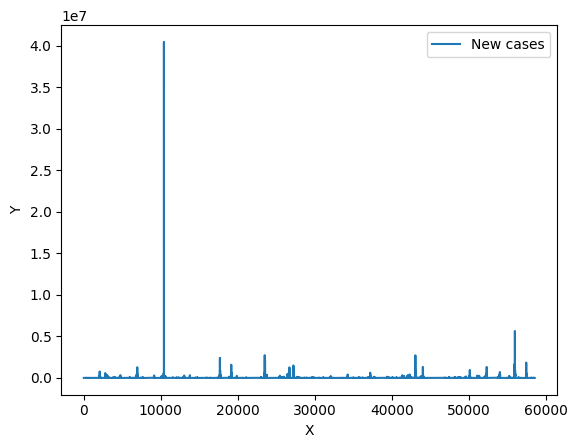

In [142]:
index = df[df["New_cases"] < 0].index
df = df.drop(index)
df["New_cases"].plot(label = "New cases", legend=True, xlabel="X", ylabel="Y")

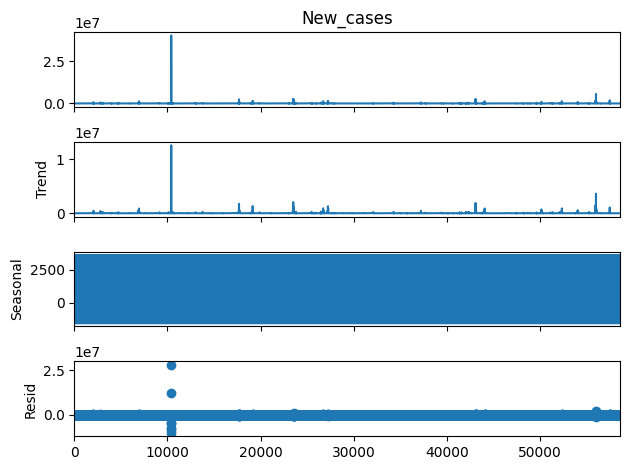

In [143]:
from statsmodels.tsa.seasonal import seasonal_decompose 
import matplotlib.pyplot as plt 

result = seasonal_decompose(df["New_cases"], period=7)
result.plot()
plt.show()

Date_reported
2020-01-05        2.0
2020-01-12       45.0
2020-01-19       90.0
2020-01-26     1896.0
2020-02-02    12538.0
               ...   
2024-08-04    61561.0
2024-08-11    62947.0
2024-08-18    61055.0
2024-08-25    62487.0
2024-09-01    63361.0
Name: New_cases, Length: 244, dtype: float64


<Axes: xlabel='Date_reported'>

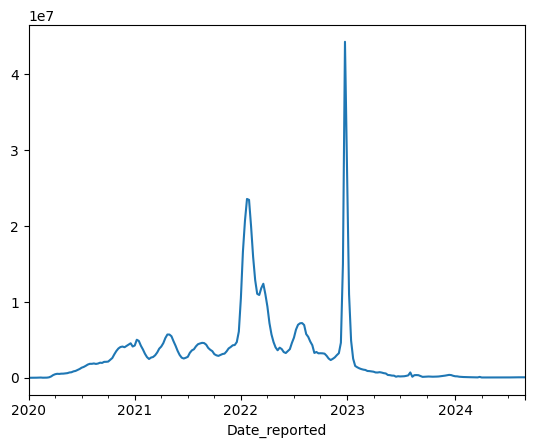

In [144]:
group = df.groupby("Date_reported")["New_cases"].sum()
print(group)
group.plot()

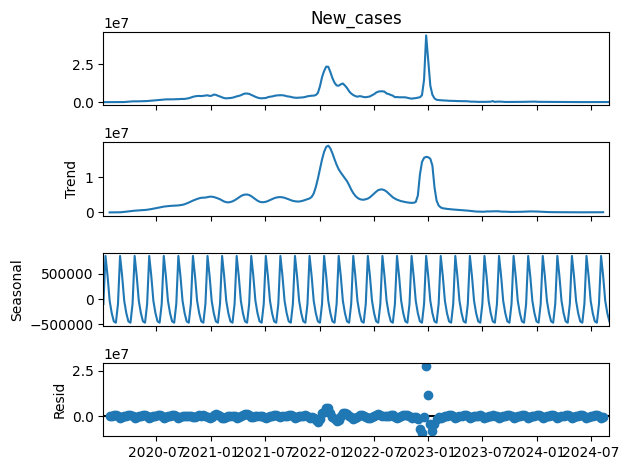

In [145]:
result = seasonal_decompose(group, period=7)
result.plot()
plt.show()

Moving average

<Axes: >

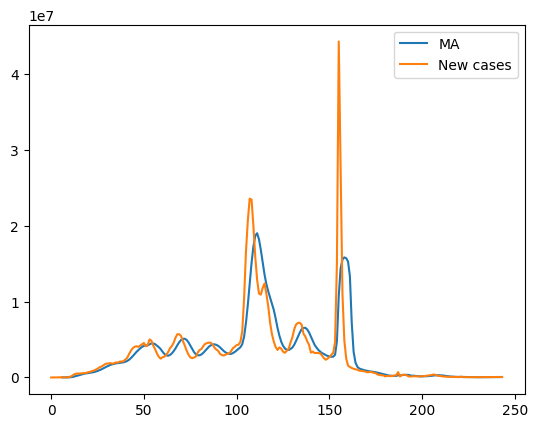

In [146]:
cases = group.reset_index()
cases["Moving_avg"] = cases["New_cases"].rolling(window=7).mean()
cases[["New_cases", "Moving_avg"]].head(10)
cases["Moving_avg"].plot(label = "MA", legend=True)
cases["New_cases"].plot(label = "New cases", legend=True)

Exponential smoothing

Exponential smoothing : 
1. Single (data harus stasioner(tanpa tren / seasonal))
2. Double (cocok untuk data tanpa seasonal)
3. Triple (cocok untuk data dengan tren dan seasonal)

trend / seasonal : 
1. None (tidak ada)
2. add (pola linear / konstan)
3. multiplicative / mul (pola non-linear / tidak konstan)

In [147]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

single = ExponentialSmoothing(group.values, trend=None, seasonal=None).fit()
double = ExponentialSmoothing(group.values, trend="add", seasonal=None).fit()
triple = ExponentialSmoothing(group.values, trend="add", seasonal="add", seasonal_periods=7).fit()

exponential = pd.DataFrame({
    "Single" : single.fittedvalues,
    "Double" : double.fittedvalues,
    "Triple" : triple.fittedvalues
})

exponential.head()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


,Single,Double,Triple
0,-2154.800000,190.090909,-39475.824119
1,-8.784000,2347.812649,30305.054940
2,44.731080,2401.157127,16732.233460
3,89.773655,2445.968890,12581.824165
4,1886.968868,4243.108227,31438.486022


In [148]:
week = 3
single_forecast = single.forecast(steps = week)
double_forecast = double.forecast(steps = week)
triple_forecast = triple.forecast(steps = week)

data = 50
group_tail = group.tail(data)
index_future = pd.date_range(start=group.index[-1], periods=week, freq = "W")

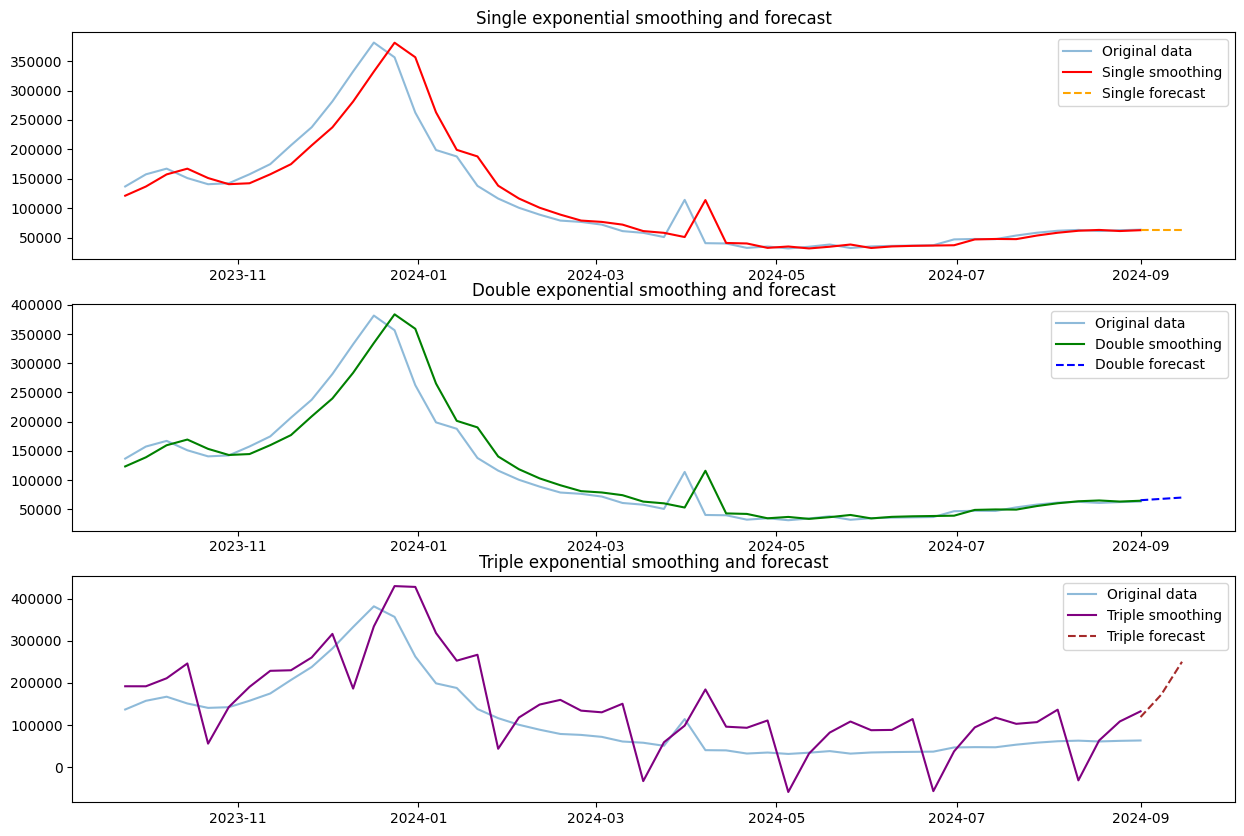

In [150]:
plt.figure(figsize=(15,10))

plt.subplot(3,1,1) # (baris, kolom, letak)
plt.plot(group_tail.index, group_tail.values, label = "Original data", alpha = 0.5)
plt.plot(group_tail.index, single.fittedvalues[-data:], label = "Single smoothing", color = "red")
plt.plot(index_future, single_forecast, label = "Single forecast", linestyle = "--", color = "orange")
plt.title("Single exponential smoothing and forecast")
plt.legend()

plt.subplot(3,1,2) # (baris, kolom, letak)
plt.plot(group_tail.index, group_tail.values, label = "Original data", alpha = 0.5)
plt.plot(group_tail.index, double.fittedvalues[-data:], label = "Double smoothing", color = "green")
plt.plot(index_future, double_forecast, label = "Double forecast", linestyle = "--", color = "blue")
plt.title("Double exponential smoothing and forecast")
plt.legend()

plt.subplot(3,1,3) # (baris, kolom, letak)
plt.plot(group_tail.index, group_tail.values, label = "Original data", alpha = 0.5)
plt.plot(group_tail.index, triple.fittedvalues[-data:], label = "Triple smoothing", color = "purple")
plt.plot(index_future, triple_forecast, label = "Triple forecast", linestyle = "--", color = "brown")
plt.title("Triple exponential smoothing and forecast")
plt.legend()